# CA1 / CA2 / CA3 marker specificity check (STARmap PLUS)

**Companion notebook to `11b_STARmapPLUS_BivariateMoransI_python.ipynb`**, following up on the
CA1/CA2/CA3 enrichment found among the top local Moran's I cells for the Spon1 -> App pair.

`top_level_cell_type` calls CA1, CA2, and CA3 are each a single cluster in this STARmap PLUS
dataset (no further sub-typing). Before trusting a Moran's-I colocalization hotspot as "these
are genuine CA1/CA2/CA3 pyramidal neurons," this notebook checks whether the genes that most
distinguish each subfield from the rest of the tissue are *specific* to it, or whether some of
them are also canonical markers of another resident cell type (astrocyte, OPC, oligodendrocyte,
microglia, vascular, DG granule, inhibitory neuron, SMC/pericyte). Overlap there would point at
either a genuine mixed transcriptional state or a segmentation/spillover artifact bleeding
another cell type's markers into the CA calls -- the same question raised earlier for the
"Cajal-Retzius" cluster, applied here.

**Steps:**
1. Load the same expression/metadata export `11b` uses.
2. Run a one-vs-rest Wilcoxon marker test (`scanpy.tl.rank_genes_groups`) for CA1, CA2, and CA3
   against every other cell in the tissue -- top markers are found empirically, not assumed.
3. Take each subfield's top-N markers by score and flag which ones are also on a canonical
   marker list for another cell type.
4. Export a full marker table with overlap flags.
5. Draw a marker-specificity dot plot: top CA1/CA2/CA3 markers (columns) x mean expression &
   detection fraction in every `top_level_cell_type` (rows) -- so any cross-reactivity is
   visible directly, rather than inferred from a name match alone.


## Imports

In [1]:
import numpy as np
import pandas as pd
import scipy.io as sio
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt

## Config

`out_dir` is where the marker-overlap CSV and the dot plot PNG get written. Switch
`celltype_col` to `"celltype_merged"` if you'd rather use the merged cell-type labels instead
of `top_level_cell_type`.

`other_celltype_markers` are canonical marker panels for every OTHER resident cell type in this
tissue -- used only to check for overlap with CA1/2/3's own empirical top markers, never to call
cell types themselves. These get filtered below to genes actually present in the STARmap PLUS
gene panel.

In [2]:
export_dir    = "starmap_plus_processed/starmap_hpc_export"
out_dir       = "starmap_plus_processed"          # where CSV/PNG outputs are written
celltype_col  = "top_level_cell_type"             # switch to "celltype_merged" if preferred
ca_groups     = ["CA1", "CA2", "CA3"]
n_top_markers = 30                                # top-N markers per subfield checked for overlap
n_dotplot_genes_per_group = 12                    # top-N per subfield shown in the dot plot

other_celltype_markers = {
    "Astrocyte":       ["Gfap", "Aqp4", "Slc1a3", "Aldh1l1", "Gja1"],
    "OPC":             ["Pdgfra", "Cspg4", "Sox10", "Olig1", "Olig2"],
    "Oligodendrocyte": ["Mbp", "Plp1", "Mog", "Mag"],
    "Microglia":       ["Cx3cr1", "C1qa", "C1qb", "Csf1r", "P2ry12", "Aif1"],
    "Vascular/Endo":   ["Cldn5", "Flt1", "Pecam1", "Cdh5"],
    "SMC/Pericyte":    ["Rgs5", "Acta2", "Myh11", "Pdgfrb", "Notch3"],
    "DG granule":      ["Prox1", "Dsp", "C1ql2"],
    "Inhibitory":      ["Gad1", "Gad2", "Pvalb", "Sst", "Vip"],
}

## Load data

Same export `11b` uses (expression matrix, genes, cells, metadata).

In [3]:
print("Loading expression matrix, genes, cells, metadata ...")
expr  = sio.mmread(f"{export_dir}/expr_norm.mtx").tocsr().T   # genes x cells -> cells x genes
genes = pd.read_csv(f"{export_dir}/genes.txt", header=None)[0].astype(str).tolist()
cells = pd.read_csv(f"{export_dir}/cells.txt", header=None)[0].astype(str).tolist()
meta  = pd.read_csv(f"{export_dir}/metadata.csv").set_index("cell_id").loc[cells]

adata = ad.AnnData(X=expr, obs=meta, var=pd.DataFrame(index=genes))
adata.var_names_make_unique()

if celltype_col not in adata.obs.columns:
    raise KeyError(f"'{celltype_col}' not in metadata columns: {adata.obs.columns.tolist()}")

adata.obs[celltype_col] = adata.obs[celltype_col].astype("category")
print(f"{adata.n_obs} cells x {adata.n_vars} genes.")
print(f"'{celltype_col}' counts:")
adata.obs[celltype_col].value_counts()

Loading expression matrix, genes, cells, metadata ...


16278 cells x 2766 genes.
'top_level_cell_type' counts:


top_level_cell_type
DG        4959
CA1       2706
Astro     1751
CA3       1544
Oligo     1152
Endo       828
CA2        768
Inh        659
Micro      605
SMC        583
OPC        301
CTX-Ex     298
LHb        124
Name: count, dtype: int64

In [4]:
missing_groups = [g for g in ca_groups if g not in adata.obs[celltype_col].cat.categories]
if missing_groups:
    raise KeyError(f"{missing_groups} not found in '{celltype_col}'. "
                    f"Available: {adata.obs[celltype_col].cat.categories.tolist()}")
adata

AnnData object with n_obs × n_vars = 16278 × 2766
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'NAME', 'biosample_id', 'donor_id', 'species', 'species__ontology_label', 'sex', 'disease', 'disease__ontology_label', 'organ', 'organ__ontology_label', 'library_preparation_protocol', 'library_preparation_protocol__ontology_label', 'orig_index', 'batch', 'time', 'group', 'replicate', 'label', 'region', 'region_merged', 'top_level_cell_type', 'sub_level_cell_type', 'celltype_merged'

## One-vs-rest marker test for CA1, CA2, CA3

Empirical -- no assumed marker list. `pts=True` also returns the fraction of cells expressing
each gene inside vs. outside the group (`pct_nz_group` / `pct_nz_reference`), useful for judging
how broadly a "marker" is actually detected.

In [5]:
print("Running Wilcoxon rank_genes_groups (one-vs-rest) for CA1 / CA2 / CA3 ...")
sc.tl.rank_genes_groups(
    adata, groupby=celltype_col, groups=ca_groups, reference="rest",
    method="wilcoxon", pts=True,
)

marker_tables = {}
for grp in ca_groups:
    tbl = sc.get.rank_genes_groups_df(adata, group=grp).sort_values("scores", ascending=False)
    tbl = tbl.reset_index(drop=True)
    marker_tables[grp] = tbl
    cols_to_show = [c for c in ["names", "logfoldchanges", "pvals_adj", "pct_nz_group", "pct_nz_reference"]
                     if c in tbl.columns]
    print(f"\nTop 10 empirical markers, {grp} vs rest of tissue:")
    print(tbl.head(10)[cols_to_show].to_string(index=False))

Running Wilcoxon rank_genes_groups (one-vs-rest) for CA1 / CA2 / CA3 ...



Top 10 empirical markers, CA1 vs rest of tissue:
  names  logfoldchanges     pvals_adj  pct_nz_group  pct_nz_reference
 Tmsb4x        2.539542  0.000000e+00      0.973023          0.697097
 Grin2b        3.380864  0.000000e+00      0.806726          0.335986
Rasgrp1        3.424922  0.000000e+00      0.775684          0.305482
 Ppp3r1        3.059441  0.000000e+00      0.910200          0.487327
   Hpca        3.254003  0.000000e+00      0.781227          0.328912
   Pfn2        2.892944 7.068897e-297      0.828529          0.408341
  Prkcb        3.636748 1.626738e-281      0.569106          0.137268
   Dkk3        3.529841 1.441096e-269      0.566519          0.136531
  Pde1a        3.508089 1.279605e-260      0.552476          0.129826
  Vsnl1        2.811841 2.045148e-249      0.837398          0.422856

Top 10 empirical markers, CA2 vs rest of tissue:
  names  logfoldchanges     pvals_adj  pct_nz_group  pct_nz_reference
   Hpca        3.059511 1.736580e-109      0.755208         

## Flag overlap with canonical markers of OTHER cell types

For each CA subfield's top-N markers, check whether the gene is also on a canonical marker list
for astrocyte, OPC, oligodendrocyte, microglia, vascular, SMC/pericyte, DG granule, or
inhibitory-neuron identity.

In [6]:
present_other_markers = {
    ct: [g for g in gl if g in adata.var_names] for ct, gl in other_celltype_markers.items()
}
print("Canonical marker genes of OTHER cell types actually present in this gene panel:")
for ct, gl in present_other_markers.items():
    print(f"  {ct:17s}: {gl if gl else '(none in panel)'}")

gene_to_other_types = {}
for ct, gl in present_other_markers.items():
    for g in gl:
        gene_to_other_types.setdefault(g, []).append(ct)

Canonical marker genes of OTHER cell types actually present in this gene panel:
  Astrocyte        : ['Gfap', 'Aqp4', 'Slc1a3', 'Aldh1l1', 'Gja1']
  OPC              : ['Pdgfra', 'Cspg4', 'Sox10', 'Olig1', 'Olig2']
  Oligodendrocyte  : ['Mbp', 'Plp1', 'Mog', 'Mag']
  Microglia        : ['Cx3cr1', 'C1qa', 'C1qb', 'Csf1r', 'P2ry12', 'Aif1']
  Vascular/Endo    : ['Cldn5', 'Flt1']
  SMC/Pericyte     : ['Rgs5', 'Acta2', 'Myh11', 'Pdgfrb']
  DG granule       : ['Prox1', 'C1ql2']
  Inhibitory       : ['Gad1', 'Gad2', 'Pvalb', 'Sst', 'Vip']


In [7]:
overlap_rows = []
for grp in ca_groups:
    top = marker_tables[grp].head(n_top_markers).copy()
    top["overlaps_other_celltype"] = top["names"].map(lambda g: ", ".join(gene_to_other_types.get(g, [])))
    top["ca_subfield"] = grp
    overlap_rows.append(top)

    hit = top[top["overlaps_other_celltype"] != ""]
    print(f"\n{grp}: {len(hit)}/{n_top_markers} top markers are ALSO canonical markers "
          f"of another cell type.")
    if len(hit):
        print(hit[["names", "overlaps_other_celltype"]].to_string(index=False))

overlap_df = pd.concat(overlap_rows, ignore_index=True)
overlap_csv = f"{out_dir}/ca_subfield_marker_overlap.csv"
overlap_df.to_csv(overlap_csv, index=False)
print(f"\nSaved full top-{n_top_markers} marker table (with overlap flags) for CA1/CA2/CA3 -> {overlap_csv}")


CA1: 0/30 top markers are ALSO canonical markers of another cell type.

CA2: 0/30 top markers are ALSO canonical markers of another cell type.

CA3: 0/30 top markers are ALSO canonical markers of another cell type.

Saved full top-30 marker table (with overlap flags) for CA1/CA2/CA3 -> starmap_plus_processed/ca_subfield_marker_overlap.csv


## Marker-specificity dot plot

Top CA1/CA2/CA3 markers (columns) x mean expression & detection fraction in every cell type
(rows). This is the more convincing check: a shared gene *name* with low expression elsewhere is
much less concerning than a marker that's genuinely co-expressed in another cell type. CA
subfields are listed first so they're easy to compare against every other row.

Building marker-specificity dot plot for 22 genes (top 12 markers each of CA1/CA2/CA3, de-duplicated) across all 13 cell types ...


Saved marker-specificity dot plot -> starmap_plus_processed/ca_subfield_marker_specificity_dotplot.png


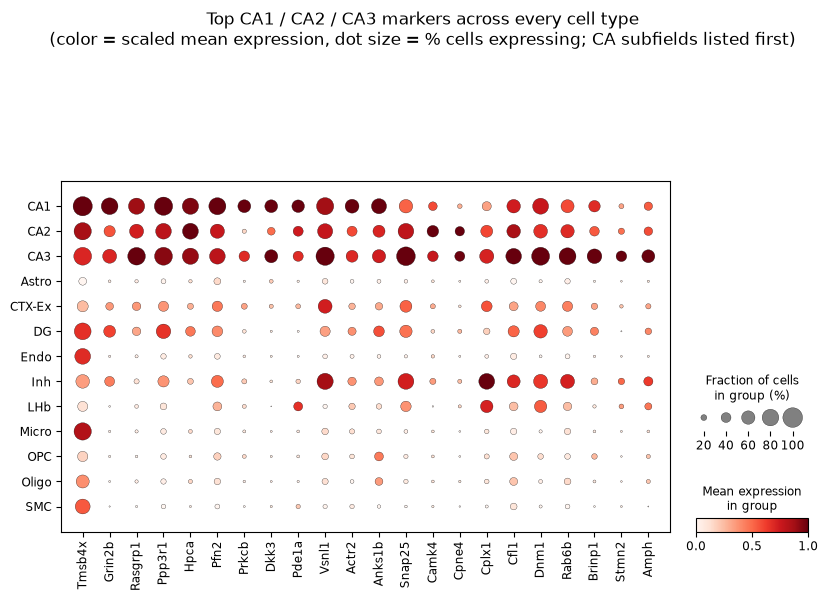

In [8]:
dotplot_genes = []
for grp in ca_groups:
    for g in marker_tables[grp].head(n_dotplot_genes_per_group)["names"].tolist():
        if g not in dotplot_genes:
            dotplot_genes.append(g)

all_cats = adata.obs[celltype_col].cat.categories.tolist()
cat_order = sorted(all_cats, key=lambda c: (c not in ca_groups, c))

print(f"Building marker-specificity dot plot for {len(dotplot_genes)} genes "
      f"(top {n_dotplot_genes_per_group} markers each of CA1/CA2/CA3, de-duplicated) "
      f"across all {len(all_cats)} cell types ...")

sc.pl.dotplot(
    adata, var_names=dotplot_genes, groupby=celltype_col,
    categories_order=cat_order, standard_scale="var", dendrogram=False, show=False,
)
plt.gcf().suptitle(
    "Top CA1 / CA2 / CA3 markers across every cell type\n"
    "(color = scaled mean expression, dot size = % cells expressing; CA subfields listed first)",
    y=1.05,
)
dotplot_png = f"{out_dir}/ca_subfield_marker_specificity_dotplot.png"
plt.savefig(dotplot_png, dpi=200, bbox_inches="tight")
print(f"Saved marker-specificity dot plot -> {dotplot_png}")
plt.show()

## Notes on interpretation

If any CA1/CA2/CA3 marker lights up strongly in a non-CA row of the dot plot (not just a
name-match in the overlap CSV), that's the more convincing signal of cross-reactivity/spillover.

One thing to watch for: `rank_genes_groups` with `method="wilcoxon"` ranks by test-statistic
significance, which favors genes with the largest, most significant difference from "everything
else" -- generic pan-neuronal/synaptic-vesicle genes (e.g. `Snap25`, `Vsnl1`, `Cplx1`) can rank
very high this way simply because they're off in every glial cell, even though they don't
actually distinguish CA1 from an interneuron or a DG granule cell. The dot plot makes this
visible: look for markers that stay dark in the CA1/CA2/CA3 rows *and* pale in Inh/DG/LHb/CTX-Ex
(not just pale in the glial rows) as the more genuinely subfield-specific candidates. A natural
follow-up is re-ranking by a specificity score (e.g. filtering on `pct_nz_reference`, or running
one-vs-each-neuron-type contrasts instead of one-vs-rest) if that distinction matters for a
downstream use of these markers.

## Confirming pyramidal/excitatory identity directly

The overlap check above rules out the CA1/2/3 markers being canonical markers of *other*
resident cell types, but it doesn't yet positively confirm that CA1/CA2/CA3 (and DG) are
genuinely principal/pyramidal-type neurons, as opposed to some other excitatory-adjacent
population. This section checks the STARmap PLUS gene panel directly for textbook
excitatory/pyramidal identity markers (`Camk2a`, `Slc17a7`/VGLUT1, `Slc17a6`/VGLUT2,
`Neurod6`, `Satb2`, `Tbr1`, `Emx1`, `Nrgn`) plus an inhibitory contrast (`Gad1`, `Gad2`,
`Slc32a1`/VGAT), and looks at their actual detection rate and expression level per cell
type -- since being present in the panel doesn't guarantee a gene is reliably detected by
this particular assay.

In [9]:
pyramidal_markers  = ["Camk2a", "Slc17a7", "Slc17a6", "Neurod6", "Satb2", "Tbr1", "Emx1", "Nrgn"]
inhibitory_markers  = ["Gad1", "Gad2", "Slc32a1"]
identity_gene_panel = pyramidal_markers + inhibitory_markers

present = [g for g in identity_gene_panel if g in adata.var_names]
missing = [g for g in identity_gene_panel if g not in adata.var_names]
print(f"{len(present)}/{len(identity_gene_panel)} identity markers present in the STARmap PLUS panel.")
if missing:
    print(f"Not in panel (skipped below): {missing}")

identity_cat_order = ["CA1", "CA2", "CA3", "DG", "CTX-Ex", "LHb", "Inh",
                       "Astro", "OPC", "Oligo", "Micro", "Endo", "SMC"]
identity_cat_order = [c for c in identity_cat_order if c in adata.obs[celltype_col].cat.categories]

11/11 identity markers present in the STARmap PLUS panel.


In [10]:
X_id = adata[:, present].X
X_id = np.asarray(X_id.todense()) if hasattr(X_id, "todense") else np.asarray(X_id)
id_df = pd.DataFrame(X_id, columns=present, index=adata.obs_names)
id_df[celltype_col] = adata.obs[celltype_col].values

mean_by_ct = id_df.groupby(celltype_col, observed=True)[present].mean().loc[identity_cat_order]
pct_by_ct  = id_df.groupby(celltype_col, observed=True)[present].apply(lambda g: (g > 0).mean()).loc[identity_cat_order]

print("=== Mean log-norm expression per cell type ===")
print(mean_by_ct.round(2).to_string())
print("\n=== Fraction of cells expressing (>0) per cell type (%) ===")
print((pct_by_ct * 100).round(0).astype(int).to_string())

=== Mean log-norm expression per cell type ===
                     Camk2a  Slc17a7  Slc17a6  Neurod6  Satb2  Tbr1  Emx1  Nrgn  Gad1  Gad2  Slc32a1
top_level_cell_type                                                                                 
CA1                    0.07     0.26     0.05     0.06   0.03  0.28  0.05  4.90  0.35  0.01     0.08
CA2                    0.08     0.50     0.05     0.08   0.08  0.32  0.03  3.97  0.28  0.01     0.06
CA3                    0.12     0.59     0.07     0.08   0.06  0.41  0.06  4.69  0.33  0.02     0.12
DG                     0.04     0.23     0.06     0.02   0.03  0.39  0.03  5.20  0.38  0.01     0.06
CTX-Ex                 0.03     0.10     0.05     0.04   0.01  0.14  0.00  2.12  0.24  0.03     0.06
LHb                    0.10     0.00     0.06     0.00   0.09  0.23  0.00  0.81  0.13  0.00     0.04
Inh                    0.10     0.08     0.03     0.05   0.04  0.24  0.03  1.23  1.67  0.24     1.37
Astro                  0.03     0.08     0.0

                     Camk2a  Slc17a7  Slc17a6  Neurod6  Satb2  Tbr1  Emx1  Nrgn  Gad1  Gad2  Slc32a1
top_level_cell_type                                                                                 
CA1                       2        7        1        2      1     8     1    97    10     0        2
CA2                       2       13        1        2      2     9     1    82     8     0        2
CA3                       4       17        2        2      2    12     2    95    10     1        4
DG                        1        6        2        1      1    10     1    97    10     0        1
CTX-Ex                    1        2        1        1      0     3     0    41     6     1        1
LHb                       2        0        2        0      2     6     0    19     3     0        1
Inh                       3        2        1        1      1     7     1    29    41     6       36
Astro                     1        2        1        1      0     3     2    17     7     0

Saved identity-marker dot plot -> starmap_plus_processed/pyramidal_marker_confirmation_dotplot.png


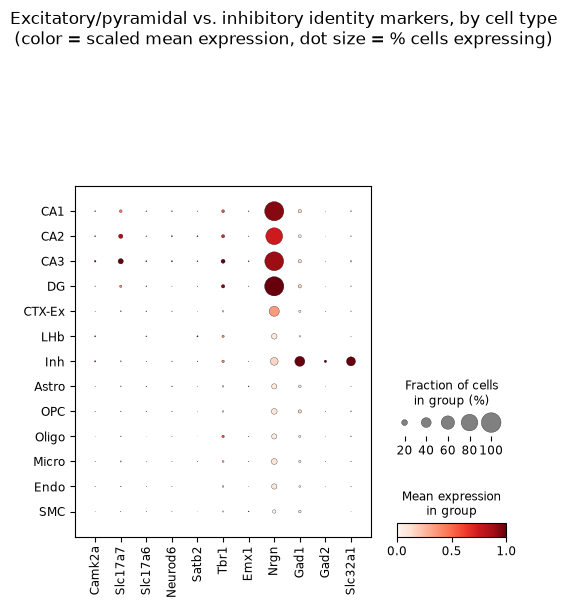

In [11]:
sc.pl.dotplot(
    adata, var_names=present, groupby=celltype_col,
    categories_order=identity_cat_order, standard_scale="var", dendrogram=False, show=False,
)
plt.gcf().suptitle(
    "Excitatory/pyramidal vs. inhibitory identity markers, by cell type\n"
    "(color = scaled mean expression, dot size = % cells expressing)", y=1.06,
)
identity_png = f"{out_dir}/pyramidal_marker_confirmation_dotplot.png"
plt.savefig(identity_png, dpi=200, bbox_inches="tight")
print(f"Saved identity-marker dot plot -> {identity_png}")
plt.show()

**Reading this:** most of the textbook markers (`Camk2a`, `Slc17a7`, `Satb2`, `Tbr1`,
`Emx1`) are detected in only a small fraction of cells even within CA1/CA2/CA3 -- almost
certainly a targeted-panel probe-efficiency limitation for these specific transcripts rather
than genuine absence, since STARmap-type panels vary a lot in per-gene capture efficiency.
`Nrgn` (neurogranin) is the one that actually behaves as expected and gives a clean,
near-binary signal: high detection and expression in CA1/CA2/CA3/DG, versus much lower
detection in Inh, LHb, and every glial type -- the best available panel-validated evidence
that these clusters are genuinely principal/pyramidal (or granule, for DG) neurons. `Gad1`
and `Slc32a1` show the mirror-image pattern, elevated specifically in Inh, which cross-checks
that the "Inh" label is a real, distinct GABAergic population rather than spillover.

## Spatial distribution of OPC cells

Where OPC cells actually sit in the tissue (using the real spatial coordinates, not an
expression-based embedding) -- all cell types shown for context, then OPC highlighted against
everything else in grey, same style as the earlier CA1/Inh/LHb spatial map.

Saved OPC spatial distribution figure -> starmap_plus_processed/opc_spatial_distribution.png


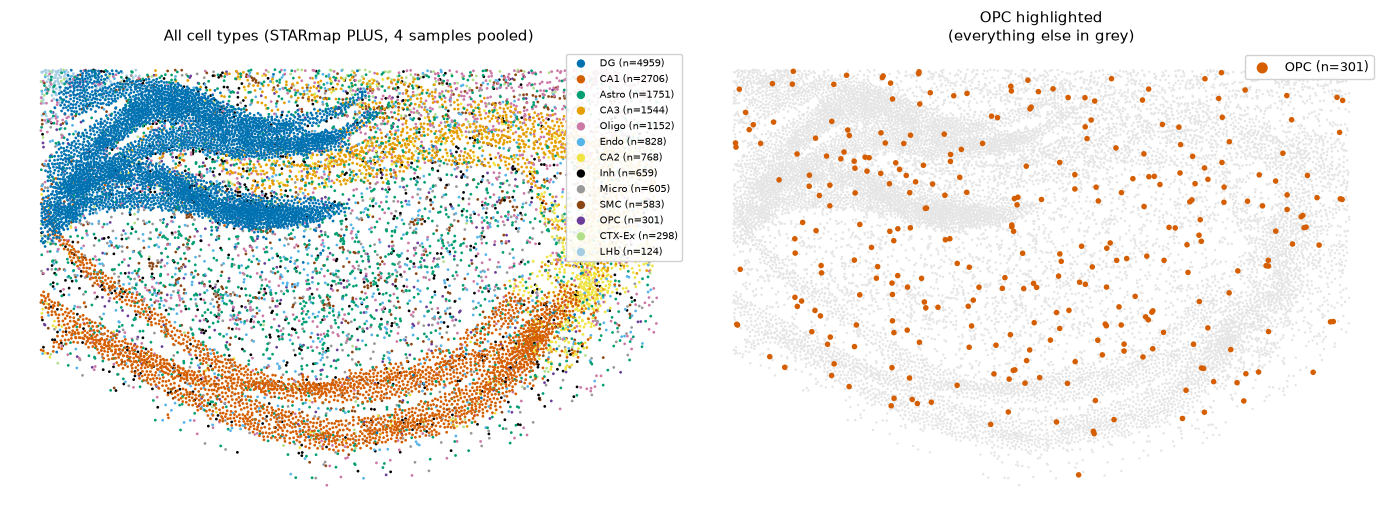

In [12]:
coords_full = pd.read_csv(f"{export_dir}/coordinates.csv").set_index("cell_id").loc[adata.obs_names]
spatial_xy = coords_full[["spatial_1", "spatial_2"]].to_numpy()
ct = adata.obs[celltype_col]
cell_types_all = ct.value_counts().index.tolist()

# Fixed-order categorical palette (Okabe-Ito extended), same scheme used elsewhere in this project
palette = [
    "#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9", "#F0E442",
    "#000000", "#999999", "#8B4513", "#6A3D9A", "#B2DF8A", "#A6CEE3",
]
color_map = {c: palette[i % len(palette)] for i, c in enumerate(cell_types_all)}

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))

# Panel A: all cell types, spatial
ax = axes[0]
for c in cell_types_all[::-1]:  # draw rarest last so small populations aren't buried
    m = (ct == c).to_numpy()
    ax.scatter(spatial_xy[m, 0], spatial_xy[m, 1], s=4, color=color_map[c],
               edgecolors="none", label=f"{c} (n={int(m.sum())})")
ax.set_aspect("equal")
ax.invert_yaxis()
ax.axis("off")
ax.set_title("All cell types (STARmap PLUS, 4 samples pooled)", fontsize=11)
handles, labels = ax.get_legend_handles_labels()
order = [labels.index(f"{c} (n={int((ct == c).sum())})") for c in cell_types_all]
ax.legend([handles[i] for i in order], [labels[i] for i in order],
           markerscale=3, fontsize=7.5, loc="upper right", framealpha=0.9)

# Panel B: OPC highlighted against everything else in grey
ax2 = axes[1]
bg = (ct != "OPC").to_numpy()
ax2.scatter(spatial_xy[bg, 0], spatial_xy[bg, 1], s=3, color="#e5e5e5", edgecolors="none")
m = (ct == "OPC").to_numpy()
ax2.scatter(spatial_xy[m, 0], spatial_xy[m, 1], s=16, color="#D55E00",
            edgecolors="none", label=f"OPC (n={int(m.sum())})")
ax2.set_aspect("equal")
ax2.invert_yaxis()
ax2.axis("off")
ax2.set_title("OPC highlighted\n(everything else in grey)", fontsize=11)
ax2.legend(markerscale=2, fontsize=9, loc="upper right", framealpha=0.9)

plt.tight_layout()
opc_spatial_png = f"{out_dir}/opc_spatial_distribution.png"
plt.savefig(opc_spatial_png, dpi=200, bbox_inches="tight")
print(f"Saved OPC spatial distribution figure -> {opc_spatial_png}")
plt.show()

**Reading this:** OPCs (n=301) are sparse but spread fairly evenly across the tissue --
present in and around DG, CA1/CA2/CA3, and the white-matter-adjacent areas, rather than
concentrated in one anatomical region. This matches the literature on OPC distribution
(ubiquitous throughout hippocampal subfields) discussed earlier, and is a useful spatial
counterpart to the UMAP-style check that OPC is also a clean, transcriptomically distinct
population.

## Which cell types are enriched among high local Moran's I cells (Spon1 -> App)

This reproduces the bivariate local Moran's I calculation from `11b_STARmapPLUS_BivariateMoransI_python.ipynb`
(same Gaussian spatial-neighbors graph, `bandwidth=400`, and the same `seed=1337`/`n_perms=200`
`li.mt.bivariate()` call) for the Spon1 -> App pair specifically, then asks: of the cells with the
highest local Moran's I score (the strongest ligand-receptor spatial colocalization signal), which
cell types are over- or under-represented relative to their tissue-wide share?

`11b` only ever plots the local score directly (spatially, and as ligand/receptor expression) --
it never actually pulls out *which cell types* dominate the top-scoring cells, which is the
question this section answers.

In [13]:
import liana as li

adata_lr = adata.copy()
coords_lr = pd.read_csv(f"{export_dir}/coordinates.csv").set_index("cell_id").loc[adata_lr.obs_names]
adata_lr.obsm["spatial"] = coords_lr[["spatial_1", "spatial_2"]].to_numpy()

li.ut.spatial_neighbors(adata_lr, bandwidth=400, kernel="gaussian", set_diag=True)

bivar_adata = li.mt.bivariate(
    adata_lr, resource_name=None, interactions=[("Spon1", "App")],
    global_name="morans", local_name="morans",
    connectivity_key="spatial_connectivities",
    n_perms=200, mask_negatives=False, add_categories=True,
    nz_prop=0, seed=1337, use_raw=False, verbose=False,
)

global_moran = bivar_adata.var.loc["Spon1^App", "morans"]
print(f"Global Moran's I (Spon1 -> App): {global_moran:.4f}")

X = bivar_adata.X
local_moran = np.asarray(X.todense()).flatten() if hasattr(X, "todense") else np.asarray(X).flatten()
print(f"Local score range: [{local_moran.min():.3f}, {local_moran.max():.3f}]")

Global Moran's I (Spon1 -> App): 0.0136
Local score range: [-2.251, 3.258]


In [14]:
top_frac = 0.05  # top 5% of cells by local Moran's I score -- same convention as 11b's fold-enrichment cell
n_top = max(1, int(top_frac * len(local_moran)))
order = local_moran.argsort()
top_idx = order[-n_top:]

top_ct = adata_lr.obs[celltype_col].iloc[top_idx]
top_counts = top_ct.value_counts(normalize=True)
bg_counts = adata_lr.obs[celltype_col].value_counts(normalize=True)
enrich = (top_counts / bg_counts).reindex(bg_counts.index).sort_values(ascending=False)

print(f"Top {top_frac:.0%} of cells by local Moran's I (n={n_top}):")
print(top_ct.value_counts())
print("\nFold enrichment vs. tissue-wide composition:")
print(enrich.round(2).to_string())

Top 5% of cells by local Moran's I (n=813):
top_level_cell_type
CA1       389
CA3       150
DG        122
CA2        56
Oligo      30
Inh        18
Endo       13
Astro      11
Micro       7
SMC         6
OPC         5
LHb         4
CTX-Ex      2
Name: count, dtype: int64

Fold enrichment vs. tissue-wide composition:
top_level_cell_type
CA1       2.88
CA3       1.95
CA2       1.46
LHb       0.65
Inh       0.55
Oligo     0.52
DG        0.49
OPC       0.33
Endo      0.31
Micro     0.23
SMC       0.21
CTX-Ex    0.13
Astro     0.13


Saved cell-type enrichment figure -> starmap_plus_processed/spon1_app_moransI_celltype_enrichment.png


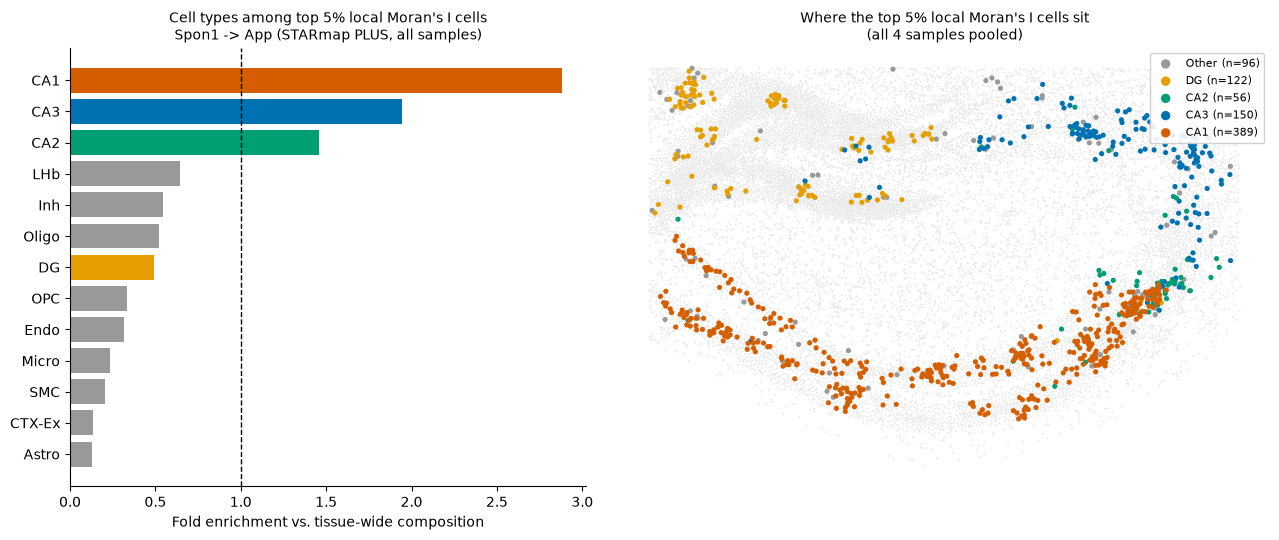

In [15]:
# Highlight the CA subfields (the ones enriched) with fixed colors, everything else grey --
# same palette convention as the CA1/Inh/LHb and OPC spatial maps above.
ca_palette = {"CA1": "#D55E00", "CA3": "#0072B2", "CA2": "#009E73", "DG": "#E69F00"}
spatial_xy_lr = adata_lr.obsm["spatial"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})

# Panel A: fold enrichment bar chart
ax = axes[0]
colors = [ca_palette.get(ct, "#999999") for ct in enrich.index]
ax.barh(enrich.index.astype(str), enrich.values, color=colors)
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Fold enrichment vs. tissue-wide composition")
ax.set_title(f"Cell types among top {top_frac:.0%} local Moran's I cells\nSpon1 -> App (STARmap PLUS, all samples)", fontsize=10)
ax.invert_yaxis()
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# Panel B: spatial map, background grey, top cells colored by cell type
ax2 = axes[1]
ax2.scatter(spatial_xy_lr[:, 0], spatial_xy_lr[:, 1], color="#e8e8e8", s=2, edgecolors="none")

top_ct_all = adata_lr.obs[celltype_col].iloc[top_idx].to_numpy()
top_xy = spatial_xy_lr[top_idx]
plot_order = ["Other"] + [c for c in ["DG", "CA2", "CA3", "CA1"] if c in ca_palette]
plot_ct = np.where(np.isin(top_ct_all, list(ca_palette.keys())), top_ct_all, "Other")
for ct in plot_order:
    m = plot_ct == ct
    if m.sum() == 0:
        continue
    ax2.scatter(top_xy[m, 0], top_xy[m, 1], color=ca_palette.get(ct, "#999999"),
                s=14, edgecolors="none", label=f"{ct} (n={int(m.sum())})")

ax2.set_aspect("equal")
ax2.invert_yaxis()
ax2.axis("off")
ax2.set_title("Where the top 5% local Moran's I cells sit\n(all 4 samples pooled)", fontsize=10)
ax2.legend(markerscale=1.8, fontsize=8, loc="upper right", framealpha=0.9)

plt.tight_layout()
enrich_png = f"{out_dir}/spon1_app_moransI_celltype_enrichment.png"
plt.savefig(enrich_png, dpi=200, bbox_inches="tight")
print(f"Saved cell-type enrichment figure -> {enrich_png}")
plt.show()

**Reading this:** CA1 is the most enriched cell type among the top 5% local Moran's I
cells (~2.9-fold over its tissue-wide share), followed by CA3 (~1.9-fold) and CA2 (~1.5-fold) --
all three CA pyramidal subfields are enriched, while DG, OPC, and every glial/vascular type are
depleted. Spatially, the highlighted cells trace out the expected hippocampal anatomy (a CA1
crescent, a CA3 arc), not a scattered or artifactual pattern -- consistent with the marker-level
checks earlier in this notebook that these are genuine CA-subfield pyramidal neurons, not a
mislabeled or contaminated population.

## Which cell types express Spon1 and App the most (baseline expression)

The section above asks which cell types dominate the *colocalization hotspot* (high local
Moran's I). This is a different, simpler question: regardless of spatial colocalization,
which cell types actually express Spon1 and App the most on average? This is baseline
expression only -- no spatial neighbors graph, no Moran's I -- just mean log-normalized
expression and the fraction of cells detected-positive, per cell type.

In [16]:
ligand_gene, receptor_gene = "Spon1", "App"

X_lig_rec = adata[:, [ligand_gene, receptor_gene]].X
X_lig_rec = np.asarray(X_lig_rec.todense()) if hasattr(X_lig_rec, "todense") else np.asarray(X_lig_rec)
expr_df = pd.DataFrame(X_lig_rec, columns=[ligand_gene, receptor_gene], index=adata.obs_names)
expr_df[celltype_col] = adata.obs[celltype_col].values

mean_by_ct = expr_df.groupby(celltype_col, observed=True)[[ligand_gene, receptor_gene]].mean()
pct_by_ct  = expr_df.groupby(celltype_col, observed=True)[[ligand_gene, receptor_gene]].apply(lambda g: (g > 0).mean())

mean_by_ct = mean_by_ct.sort_values(ligand_gene, ascending=False)
pct_by_ct  = pct_by_ct.loc[mean_by_ct.index]

print(f"Mean log-normalized expression, by cell type (sorted by {ligand_gene}):")
print(mean_by_ct.round(3).to_string())
print(f"\n% of cells expressing (>0), by cell type:")
print((pct_by_ct * 100).round(0).astype(int).to_string())

Mean log-normalized expression, by cell type (sorted by Spon1):
                     Spon1    App
top_level_cell_type              
CA1                  0.466  1.753
CA3                  0.438  1.548
DG                   0.288  0.982
Inh                  0.281  1.282
CA2                  0.229  1.255
LHb                  0.211  0.834
CTX-Ex               0.202  0.681
OPC                  0.152  0.696
Oligo                0.107  1.390
Astro                0.088  0.249
Micro                0.087  0.382
Endo                 0.078  0.930
SMC                  0.074  0.942

% of cells expressing (>0), by cell type:
                     Spon1  App
top_level_cell_type            
CA1                     13   46
CA3                     13   43
DG                       7   25
Inh                      8   33
CA2                      7   32
LHb                      5   20
CTX-Ex                   5   16
OPC                      4   16
Oligo                    3   31
Astro                    2    6

Saved baseline expression bar chart -> starmap_plus_processed/spon1_app_expression_by_celltype.png


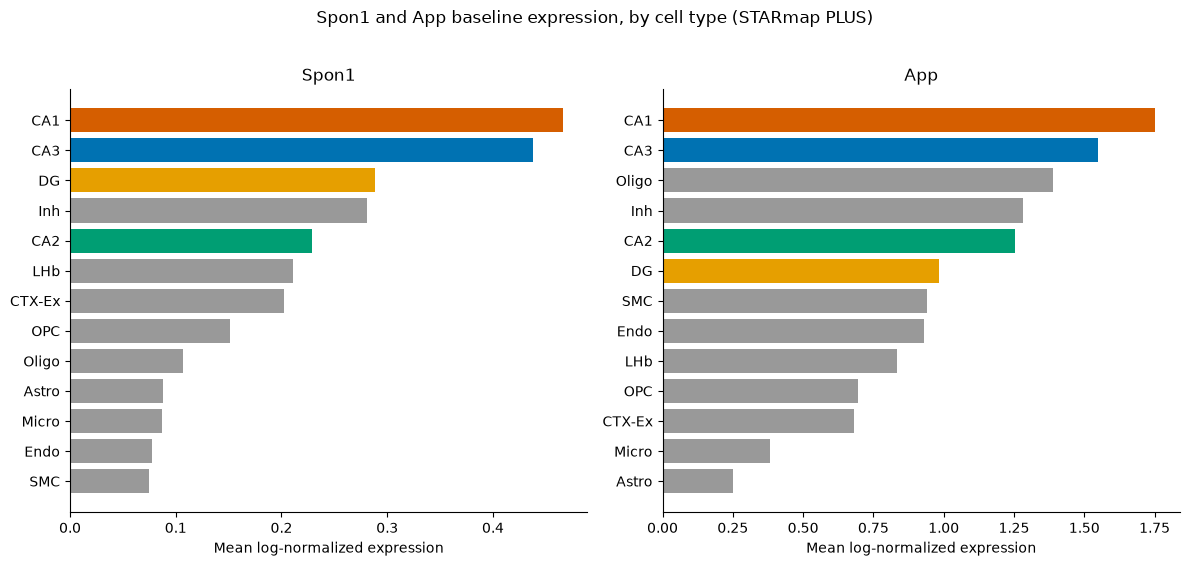

In [17]:
ca_palette = {"CA1": "#D55E00", "CA2": "#009E73", "CA3": "#0072B2", "DG": "#E69F00"}
bar_colors = [ca_palette.get(ct, "#999999") for ct in mean_by_ct.index]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=False)

for ax, gene in zip(axes, [ligand_gene, receptor_gene]):
    order = mean_by_ct[gene].sort_values(ascending=True).index  # ascending for horizontal barh (largest on top)
    colors = [ca_palette.get(ct, "#999999") for ct in order]
    ax.barh(order.astype(str), mean_by_ct.loc[order, gene], color=colors)
    ax.set_xlabel("Mean log-normalized expression")
    ax.set_title(gene, fontsize=12)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.suptitle(f"{ligand_gene} and {receptor_gene} baseline expression, by cell type (STARmap PLUS)", y=1.02)
plt.tight_layout()
expr_bar_png = f"{out_dir}/spon1_app_expression_by_celltype.png"
plt.savefig(expr_bar_png, dpi=200, bbox_inches="tight")
print(f"Saved baseline expression bar chart -> {expr_bar_png}")
plt.show()

**Reading this:** CA1 and CA3 are the top two cell types for both genes -- CA1 highest
for Spon1 (mean 0.47) and App (mean 1.75), CA3 close behind on both. OPC, by contrast, ranks
near the bottom for both (Spon1 mean 0.15, App mean 0.70; roughly 9th of 13 cell types on
detection rate for either gene). This is consistent with, and helps explain, the local
Moran's I enrichment result above: CA1/CA3/CA2 aren't just where the *colocalization* signal
concentrates, they're also where both genes are most highly expressed to begin with -- while
OPC's low ranking here lines up with OPC being depleted (not enriched) among the high local
Moran's I cells.